<a href="https://colab.research.google.com/github/drcrajc/indicon_dr/blob/main/dr_paper_revision_xception_vs_mobilenetv2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DR Paper Major-Revision Analysis — Xception vs MobileNetV2

This Colab notebook is tailored to your existing Google Drive project:

```text
MyDrive/dr_datasets_indicon/
├── datasets/
│   ├── train/
│   ├── validation/
│   └── test/
├── results/
│   ├── xception (results)/
│   │   ├── model_Xception_2classes.tflite
│   │   ├── test_results.xlsx
│   │   └── training_history_Xception_2classes.xlsx
│   └── mobilenetv2 (results)/
│       ├── model_mnv2_2classes.tflite
│       ├── test_results_mnv2.xlsx
│       └── training_history_mnv2_2classes.xlsx
└── revision_outputs/
```

The notebook reconstructs the saved experiment, checks train/validation/test counts, checks whether patient IDs can be audited from filenames, compares the two models image-by-image, runs **McNemar's exact test**, computes **bootstrap 95% confidence intervals**, and redraws Figs. 2–6 with publication-quality formatting.

**Important:** the bootstrap confidence intervals quantify uncertainty from the fixed test set. They are not repeated-training-run confidence intervals.


In [ ]:
# CELL 1 — Install required packages
!pip -q install openpyxl statsmodels scipy pillow


In [ ]:
# CELL 2 — Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# CELL 3 — Imports
import os, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)
from statsmodels.stats.contingency_tables import mcnemar

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "figure.dpi": 140,
    "savefig.dpi": 600
})


In [ ]:
# CELL 4 — Exact Drive paths
ROOT = "/content/drive/MyDrive/dr_datasets_indicon"

DATASET_DIR = os.path.join(ROOT, "datasets")
TRAIN_DIR = os.path.join(DATASET_DIR, "train")
VAL_DIR = os.path.join(DATASET_DIR, "validation")
TEST_DIR = os.path.join(DATASET_DIR, "test")

RESULTS_DIR = os.path.join(ROOT, "results")
X_DIR = os.path.join(RESULTS_DIR, "xception (results)")
M_DIR = os.path.join(RESULTS_DIR, "mobilenetv2 (results)")

X_TEST = os.path.join(X_DIR, "test_results.xlsx")
X_HIST = os.path.join(X_DIR, "training_history_Xception_2classes.xlsx")
X_TFLITE = os.path.join(X_DIR, "model_Xception_2classes.tflite")

M_TEST = os.path.join(M_DIR, "test_results_mnv2.xlsx")
M_HIST = os.path.join(M_DIR, "training_history_mnv2_2classes.xlsx")
M_TFLITE = os.path.join(M_DIR, "model_mnv2_2classes.tflite")

OUT = os.path.join(ROOT, "revision_outputs")
os.makedirs(OUT, exist_ok=True)

for p in [TRAIN_DIR, VAL_DIR, TEST_DIR, X_TEST, X_HIST, X_TFLITE, M_TEST, M_HIST, M_TFLITE]:
    print(("✓" if os.path.exists(p) else "✗"), p)


✓ /content/drive/MyDrive/dr_datasets_indicon/datasets/train
✓ /content/drive/MyDrive/dr_datasets_indicon/datasets/validation
✓ /content/drive/MyDrive/dr_datasets_indicon/datasets/test
✓ /content/drive/MyDrive/dr_datasets_indicon/results/xception (results)/test_results.xlsx
✓ /content/drive/MyDrive/dr_datasets_indicon/results/xception (results)/training_history_Xception_2classes.xlsx
✓ /content/drive/MyDrive/dr_datasets_indicon/results/xception (results)/model_Xception_2classes.tflite
✓ /content/drive/MyDrive/dr_datasets_indicon/results/mobilenetv2 (results)/test_results_mnv2.xlsx
✓ /content/drive/MyDrive/dr_datasets_indicon/results/mobilenetv2 (results)/training_history_mnv2_2classes.xlsx
✓ /content/drive/MyDrive/dr_datasets_indicon/results/mobilenetv2 (results)/model_mnv2_2classes.tflite


## 1. Dataset audit

The first check verifies image counts. The second tries to check patient-level overlap **only when original EyePACS-style filenames are still present** (for example `123_left.jpeg`, `123_right.jpeg`). If your files were renamed, the notebook will not make an unsupported patient-disjoint claim.


In [ ]:
# CELL 5 — Count images class-wise
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def class_counts(folder):
    result = {}
    root = Path(folder)
    if not root.exists():
        return result
    for d in sorted([p for p in root.iterdir() if p.is_dir()]):
        result[d.name] = sum(
            1 for f in d.rglob("*")
            if f.is_file() and f.suffix.lower() in VALID_EXT
        )
    return result

for name, folder in [("TRAIN", TRAIN_DIR), ("VALIDATION", VAL_DIR), ("TEST", TEST_DIR)]:
    c = class_counts(folder)
    print("\n", name, c, "TOTAL =", sum(c.values()))



 TRAIN {'healthy_dr': 800, 'moderate_dr': 725} TOTAL = 1525

 VALIDATION {'healthy_dr': 100, 'moderate_dr': 90} TOTAL = 190

 TEST {'healthy_dr': 100, 'moderate_dr': 90} TOTAL = 190


In [ ]:
# CELL 6 — Patient-overlap check when original EyePACS IDs are preserved
def stems(folder):
    return [
        f.stem for f in Path(folder).rglob("*")
        if f.is_file() and f.suffix.lower() in VALID_EXT
    ]

tr = stems(TRAIN_DIR)
va = stems(VAL_DIR)
te = stems(TEST_DIR)

sample = (tr + va + te)[:200]
ratio = (
    sum(bool(re.match(r"^\d+_(left|right)$", s, flags=re.I)) for s in sample)
    / max(len(sample), 1)
)

if ratio >= 0.5:
    pid = lambda items: {s.split("_")[0] for s in items}
    trp, vap, tep = pid(tr), pid(va), pid(te)

    print("Original EyePACS-style IDs detected.")
    print("Train vs validation overlap:", len(trp & vap))
    print("Train vs test overlap      :", len(trp & tep))
    print("Validation vs test overlap :", len(vap & tep))
else:
    print("WARNING: original EyePACS patient IDs are not reliably present in filenames.")
    print("Patient-level independence cannot be verified from renamed filenames alone.")


Patient-level independence cannot be verified from renamed filenames alone.


## 2. Read saved Excel results and training histories

In [ ]:
# CELL 7 — Load existing saved experiment files
x_test_raw = pd.read_excel(X_TEST)
m_test_raw = pd.read_excel(M_TEST)
x_hist_raw = pd.read_excel(X_HIST)
m_hist_raw = pd.read_excel(M_HIST)

print("Xception test columns:", x_test_raw.columns.tolist())
display(x_test_raw.head())

print("\nMobileNetV2 test columns:", m_test_raw.columns.tolist())
display(m_test_raw.head())

print("\nXception history columns:", x_hist_raw.columns.tolist())
display(x_hist_raw.head())

print("\nMobileNetV2 history columns:", m_hist_raw.columns.tolist())
display(m_hist_raw.head())


Xception test columns: ['Image Name', 'Predicted Class', 'True Class', 'Accuracy']


,Image Name,Predicted Class,True Class,Accuracy
0,Healthy_104.png,healthy_dr,healthy_dr,100%
1,Healthy_110.png,healthy_dr,healthy_dr,100%
2,Healthy_111.png,healthy_dr,healthy_dr,100%
3,Healthy_117.png,healthy_dr,healthy_dr,100%
4,Healthy_118.png,healthy_dr,healthy_dr,100%



MobileNetV2 test columns: ['Image Name', 'Predicted Class', 'True Class', 'Accuracy']


,Image Name,Predicted Class,True Class,Accuracy
0,Healthy_104.png,healthy_dr,healthy_dr,100%
1,Healthy_110.png,healthy_dr,healthy_dr,100%
2,Healthy_111.png,healthy_dr,healthy_dr,100%
3,Healthy_117.png,healthy_dr,healthy_dr,100%
4,Healthy_118.png,healthy_dr,healthy_dr,100%



Xception history columns: ['accuracy', 'loss', 'val_accuracy', 'val_loss', 'test_loss', 'test_accuracy']


,accuracy,loss,val_accuracy,val_loss,test_loss,test_accuracy
0,0.857895,0.344951,0.947368,0.190919,0.146091,0.936842
1,0.944079,0.171819,0.952632,0.162447,0.146091,0.936842
2,0.951316,0.151639,0.957895,0.137685,0.146091,0.936842
3,0.952632,0.135583,0.931579,0.167735,0.146091,0.936842
4,0.960526,0.122430,0.957895,0.120562,0.146091,0.936842



MobileNetV2 history columns: ['accuracy', 'loss', 'val_accuracy', 'val_loss', 'test_loss', 'test_accuracy']


,accuracy,loss,val_accuracy,val_loss,test_loss,test_accuracy
0,0.795395,0.915086,0.952632,0.164239,0.140346,0.952632
1,0.928947,0.215342,0.921053,0.171249,0.140346,0.952632
2,0.939474,0.191946,0.952632,0.144508,0.140346,0.952632
3,0.945395,0.161830,0.963158,0.118543,0.140346,0.952632
4,0.941447,0.166436,0.947368,0.150280,0.140346,0.952632


In [ ]:
# CELL 8 — Flexible column matching
def canon(x):
    return re.sub(r"[^a-z0-9]+", "", str(x).lower())

def find_col(df, aliases, required=True):
    mapping = {canon(c): c for c in df.columns}

    for a in aliases:
        ca = canon(a)
        if ca in mapping:
            return mapping[ca]

    for a in aliases:
        ca = canon(a)
        for k, original in mapping.items():
            if ca and (ca in k or k in ca):
                return original

    if required:
        raise KeyError(f"Could not find one of {aliases}; available columns = {list(df.columns)}")
    return None

IMAGE_ALIASES = ["image", "image_name", "filename", "file_name", "file", "test image"]
TRUE_ALIASES = ["true", "true_label", "actual", "actual_label", "ground_truth", "true class", "actual class"]
PRED_ALIASES = ["pred", "predicted", "prediction", "predicted_label", "predicted class"]

def normalize_label(v):
    if pd.isna(v):
        return np.nan

    if isinstance(v, (int, np.integer)):
        return int(v)
    if isinstance(v, (float, np.floating)) and float(v).is_integer():
        return int(v)

    s = canon(v)

    if "healthy" in s or s in {"nodr", "normal", "0", "class0"}:
        return 0
    if "moderate" in s or s in {"1", "class1"}:
        return 1

    raise ValueError(f"Unknown class label: {v!r}")

def standardize_results(df, model):
    ic = find_col(df, IMAGE_ALIASES)
    tc = find_col(df, TRUE_ALIASES)
    pc = find_col(df, PRED_ALIASES)

    out = pd.DataFrame({
        "image_original": df[ic].astype(str),
        "image_key": df[ic].map(lambda x: Path(str(x)).stem.lower().strip()),
        "true_label": df[tc].map(normalize_label).astype(int),
        "pred_label": df[pc].map(normalize_label).astype(int)
    })
    out["correct"] = out["true_label"] == out["pred_label"]
    out["model"] = model
    return out

x_test = standardize_results(x_test_raw, "Xception")
m_test = standardize_results(m_test_raw, "MobileNetV2")

display(x_test.head())
display(m_test.head())
print("Xception N:", len(x_test), "correct:", x_test.correct.sum())
print("MobileNetV2 N:", len(m_test), "correct:", m_test.correct.sum())


,image_original,image_key,true_label,pred_label,correct,model
0,Healthy_104.png,healthy_104,0,0,True,Xception
1,Healthy_110.png,healthy_110,0,0,True,Xception
2,Healthy_111.png,healthy_111,0,0,True,Xception
3,Healthy_117.png,healthy_117,0,0,True,Xception
4,Healthy_118.png,healthy_118,0,0,True,Xception


,image_original,image_key,true_label,pred_label,correct,model
0,Healthy_104.png,healthy_104,0,0,True,MobileNetV2
1,Healthy_110.png,healthy_110,0,0,True,MobileNetV2
2,Healthy_111.png,healthy_111,0,0,True,MobileNetV2
3,Healthy_117.png,healthy_117,0,0,True,MobileNetV2
4,Healthy_118.png,healthy_118,0,0,True,MobileNetV2


Xception N: 190 correct: 178
MobileNetV2 N: 190 correct: 181


## 3. Reconstruct metrics and confusion matrices from the saved predictions

In [ ]:
# CELL 9 — Recompute metrics
CLASS_NAMES = ["Healthy", "Moderate DR"]

def metrics(df, model):
    yt = df.true_label.to_numpy()
    yp = df.pred_label.to_numpy()

    cm = confusion_matrix(yt, yp, labels=[0,1])

    row = {
        "Model": model,
        "N": len(df),
        "Accuracy (%)": 100*accuracy_score(yt, yp),
        "Precision weighted (%)": 100*precision_score(yt, yp, average="weighted", zero_division=0),
        "Recall weighted (%)": 100*recall_score(yt, yp, average="weighted", zero_division=0),
        "F1 weighted (%)": 100*f1_score(yt, yp, average="weighted", zero_division=0),
        "Precision Moderate (%)": 100*precision_score(yt, yp, pos_label=1, zero_division=0),
        "Recall Moderate (%)": 100*recall_score(yt, yp, pos_label=1, zero_division=0),
        "F1 Moderate (%)": 100*f1_score(yt, yp, pos_label=1, zero_division=0),
    }

    print("\n", model)
    print(pd.Series(row).to_string())
    print("\nConfusion matrix:")
    print(cm)
    print("\nClass-wise report:")
    print(classification_report(yt, yp, target_names=CLASS_NAMES, digits=4, zero_division=0))

    return row, cm

x_row, x_cm = metrics(x_test, "Xception")
m_row, m_cm = metrics(m_test, "MobileNetV2")

summary = pd.DataFrame([x_row, m_row])
display(summary)



 Xception
Model                      Xception
N                               190
Accuracy (%)              93.684211
Precision weighted (%)    93.684211
Recall weighted (%)       93.684211
F1 weighted (%)           93.684211
Precision Moderate (%)    93.333333
Recall Moderate (%)       93.333333
F1 Moderate (%)           93.333333

Confusion matrix:
[[94  6]
 [ 6 84]]

Class-wise report:
              precision    recall  f1-score   support

     Healthy     0.9400    0.9400    0.9400       100
 Moderate DR     0.9333    0.9333    0.9333        90

    accuracy                         0.9368       190
   macro avg     0.9367    0.9367    0.9367       190
weighted avg     0.9368    0.9368    0.9368       190


 MobileNetV2
Model                     MobileNetV2
N                                 190
Accuracy (%)                95.263158
Precision weighted (%)      95.376677
Recall weighted (%)         95.263158
F1 weighted (%)             95.253255
Precision Moderate (%)      97.647059


,Model,N,Accuracy (%),Precision weighted (%),Recall weighted (%),F1 weighted (%),Precision Moderate (%),Recall Moderate (%),F1 Moderate (%)
0,Xception,190,93.684211,93.684211,93.684211,93.684211,93.333333,93.333333,93.333333
1,MobileNetV2,190,95.263158,95.376677,95.263158,95.253255,97.647059,92.222222,94.857143


## 4. Pair Xception and MobileNetV2 image-by-image

This is essential for McNemar's test.


In [ ]:
# CELL 10 — Merge paired predictions
paired = x_test[
    ["image_original", "image_key", "true_label", "pred_label", "correct"]
].rename(columns={
    "image_original": "x_image",
    "pred_label": "x_pred",
    "correct": "x_correct"
}).merge(
    m_test[
        ["image_original", "image_key", "true_label", "pred_label", "correct"]
    ].rename(columns={
        "image_original": "m_image",
        "true_label": "m_true",
        "pred_label": "m_pred",
        "correct": "m_correct"
    }),
    on="image_key",
    how="inner"
)

print("Paired images:", len(paired))
print("Ground-truth mismatches:", int((paired.true_label != paired.m_true).sum()))

if (paired.true_label != paired.m_true).any():
    raise ValueError("Ground truth differs between saved Xception and MobileNetV2 files.")

paired["both_correct"] = paired.x_correct & paired.m_correct
paired["x_only"] = paired.x_correct & ~paired.m_correct
paired["m_only"] = ~paired.x_correct & paired.m_correct
paired["both_wrong"] = ~paired.x_correct & ~paired.m_correct

display(paired.head())


Paired images: 190
Ground-truth mismatches: 0


,x_image,image_key,true_label,x_pred,x_correct,m_image,m_true,m_pred,m_correct,both_correct,x_only,m_only,both_wrong
0,Healthy_104.png,healthy_104,0,0,True,Healthy_104.png,0,0,True,True,False,False,False
1,Healthy_110.png,healthy_110,0,0,True,Healthy_110.png,0,0,True,True,False,False,False
2,Healthy_111.png,healthy_111,0,0,True,Healthy_111.png,0,0,True,True,False,False,False
3,Healthy_117.png,healthy_117,0,0,True,Healthy_117.png,0,0,True,True,False,False,False
4,Healthy_118.png,healthy_118,0,0,True,Healthy_118.png,0,0,True,True,False,False,False


In [ ]:
# CELL 11 — McNemar exact test
table = np.array([
    [int(paired.both_correct.sum()), int(paired.x_only.sum())],
    [int(paired.m_only.sum()), int(paired.both_wrong.sum())]
])

print("McNemar table:")
print(table)

mc = mcnemar(table, exact=True)
print("Exact McNemar statistic:", mc.statistic)
print("Exact McNemar p-value:", mc.pvalue)

if mc.pvalue < 0.05:
    print("Statistically significant paired difference at alpha = 0.05.")
else:
    print("No statistically significant paired difference at alpha = 0.05.")


McNemar table:
[[173   5]
 [  8   4]]
Exact McNemar statistic: 5.0
Exact McNemar p-value: 0.5810546875
No statistically significant paired difference at alpha = 0.05.


## 5. Bootstrap confidence intervals

The reviewer suggested bootstrap confidence intervals. We compute:

- 95% bootstrap CI for Xception test accuracy
- 95% bootstrap CI for MobileNetV2 test accuracy
- paired 95% bootstrap CI for the accuracy difference `MobileNetV2 − Xception`


In [ ]:
# CELL 12 — Bootstrap functions
def bootstrap_acc(yt, yp, n_boot=10000, seed=42):
    yt, yp = np.asarray(yt), np.asarray(yp)
    rng = np.random.default_rng(seed)
    n = len(yt)
    vals = np.empty(n_boot)

    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        vals[i] = accuracy_score(yt[idx], yp[idx])

    return {
        "point": accuracy_score(yt, yp),
        "lower": np.quantile(vals, 0.025),
        "upper": np.quantile(vals, 0.975)
    }

def paired_bootstrap_diff(yt, xp, mp, n_boot=10000, seed=42):
    yt, xp, mp = np.asarray(yt), np.asarray(xp), np.asarray(mp)
    rng = np.random.default_rng(seed)
    n = len(yt)
    vals = np.empty(n_boot)

    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        vals[i] = accuracy_score(yt[idx], mp[idx]) - accuracy_score(yt[idx], xp[idx])

    return {
        "point": accuracy_score(yt, mp) - accuracy_score(yt, xp),
        "lower": np.quantile(vals, 0.025),
        "upper": np.quantile(vals, 0.975)
    }

x_boot = bootstrap_acc(x_test.true_label, x_test.pred_label)
m_boot = bootstrap_acc(m_test.true_label, m_test.pred_label)
d_boot = paired_bootstrap_diff(paired.true_label, paired.x_pred, paired.m_pred)

print(
    f"Xception: {x_boot['point']*100:.2f}% "
    f"(95% bootstrap CI {x_boot['lower']*100:.2f}%–{x_boot['upper']*100:.2f}%)"
)

print(
    f"MobileNetV2: {m_boot['point']*100:.2f}% "
    f"(95% bootstrap CI {m_boot['lower']*100:.2f}%–{m_boot['upper']*100:.2f}%)"
)

print(
    f"MobileNetV2 − Xception = {d_boot['point']*100:.2f} percentage points "
    f"(95% paired bootstrap CI {d_boot['lower']*100:.2f} to {d_boot['upper']*100:.2f})"
)


Xception: 93.68% (95% bootstrap CI 90.00%–96.84%)
MobileNetV2: 95.26% (95% bootstrap CI 92.11%–97.89%)
MobileNetV2 − Xception = 1.58 percentage points (95% paired bootstrap CI -2.11 to 5.26)


## 6. Redraw Fig. 2 from the saved training-history Excel files

In [ ]:
# CELL 13 — Standardize history columns
def standardize_history(df):
    ec = find_col(df, ["epoch", "epochs"], required=False)
    ac = find_col(df, ["accuracy", "acc", "training_accuracy", "train_accuracy"])
    vc = find_col(df, ["val_accuracy", "validation_accuracy", "val_acc"])
    lc = find_col(df, ["loss", "training_loss", "train_loss"])
    vl = find_col(df, ["val_loss", "validation_loss"])

    epoch = np.arange(1, len(df)+1) if ec is None else pd.to_numeric(df[ec], errors="coerce").to_numpy()
    if len(epoch) and np.nanmin(epoch) == 0:
        epoch = epoch + 1

    return pd.DataFrame({
        "epoch": epoch,
        "accuracy": pd.to_numeric(df[ac], errors="coerce"),
        "val_accuracy": pd.to_numeric(df[vc], errors="coerce"),
        "loss": pd.to_numeric(df[lc], errors="coerce"),
        "val_loss": pd.to_numeric(df[vl], errors="coerce")
    }).dropna()

xh = standardize_history(x_hist_raw)
mh = standardize_history(m_hist_raw)

display(xh.head())
display(mh.head())


,epoch,accuracy,val_accuracy,loss,val_loss
0,1,0.857895,0.947368,0.344951,0.190919
1,2,0.944079,0.952632,0.171819,0.162447
2,3,0.951316,0.957895,0.151639,0.137685
3,4,0.952632,0.931579,0.135583,0.167735
4,5,0.960526,0.957895,0.122430,0.120562


,epoch,accuracy,val_accuracy,loss,val_loss
0,1,0.795395,0.952632,0.915086,0.164239
1,2,0.928947,0.921053,0.215342,0.171249
2,3,0.939474,0.952632,0.191946,0.144508
3,4,0.945395,0.963158,0.161830,0.118543
4,5,0.941447,0.947368,0.166436,0.150280


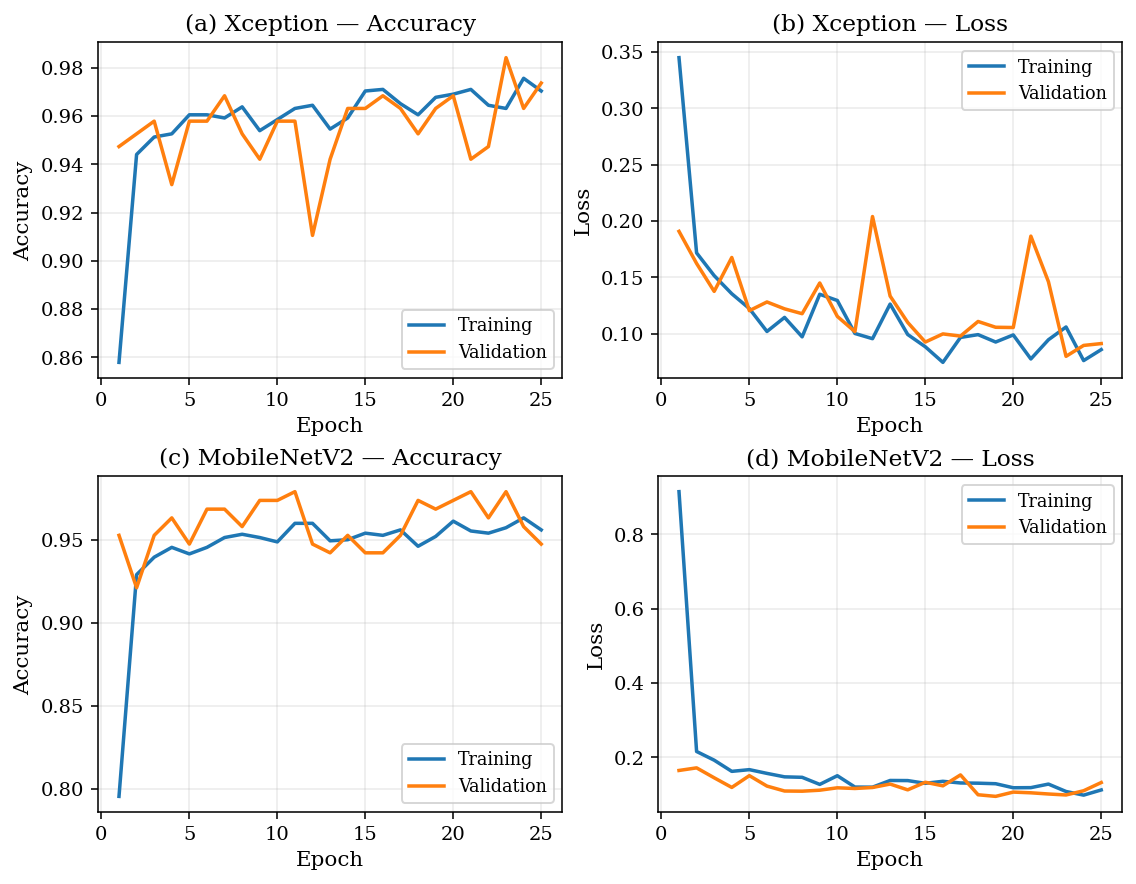

Saved: /content/drive/MyDrive/dr_datasets_indicon/revision_outputs/Fig2_revised_training_curves.png
Saved: /content/drive/MyDrive/dr_datasets_indicon/revision_outputs/Fig2_revised_training_curves.pdf


In [ ]:
# CELL 14 — Fig. 2: clean 2×2 training curves
fig, ax = plt.subplots(2, 2, figsize=(8.0, 6.2), constrained_layout=True)

ax[0,0].plot(xh.epoch, xh.accuracy, linewidth=1.8, label="Training")
ax[0,0].plot(xh.epoch, xh.val_accuracy, linewidth=1.8, label="Validation")
ax[0,0].set_title("(a) Xception — Accuracy")

ax[0,1].plot(xh.epoch, xh.loss, linewidth=1.8, label="Training")
ax[0,1].plot(xh.epoch, xh.val_loss, linewidth=1.8, label="Validation")
ax[0,1].set_title("(b) Xception — Loss")

ax[1,0].plot(mh.epoch, mh.accuracy, linewidth=1.8, label="Training")
ax[1,0].plot(mh.epoch, mh.val_accuracy, linewidth=1.8, label="Validation")
ax[1,0].set_title("(c) MobileNetV2 — Accuracy")

ax[1,1].plot(mh.epoch, mh.loss, linewidth=1.8, label="Training")
ax[1,1].plot(mh.epoch, mh.val_loss, linewidth=1.8, label="Validation")
ax[1,1].set_title("(d) MobileNetV2 — Loss")

for a in ax.ravel():
    a.set_xlabel("Epoch")
    a.grid(alpha=0.25)
    a.legend()

ax[0,0].set_ylabel("Accuracy")
ax[1,0].set_ylabel("Accuracy")
ax[0,1].set_ylabel("Loss")
ax[1,1].set_ylabel("Loss")

png = os.path.join(OUT, "Fig2_revised_training_curves.png")
pdf = os.path.join(OUT, "Fig2_revised_training_curves.pdf")
plt.savefig(png, dpi=600, bbox_inches="tight")
plt.savefig(pdf, bbox_inches="tight")
plt.show()

print("Saved:", png)
print("Saved:", pdf)


## 7. Redraw Fig. 4 — confusion matrices

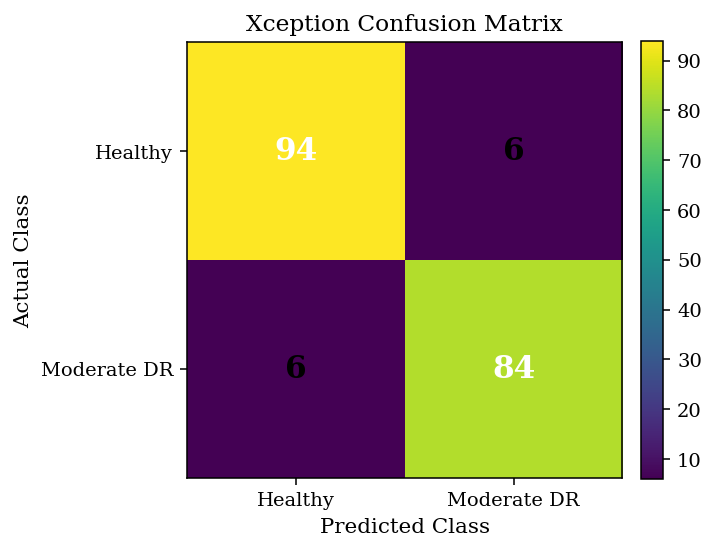

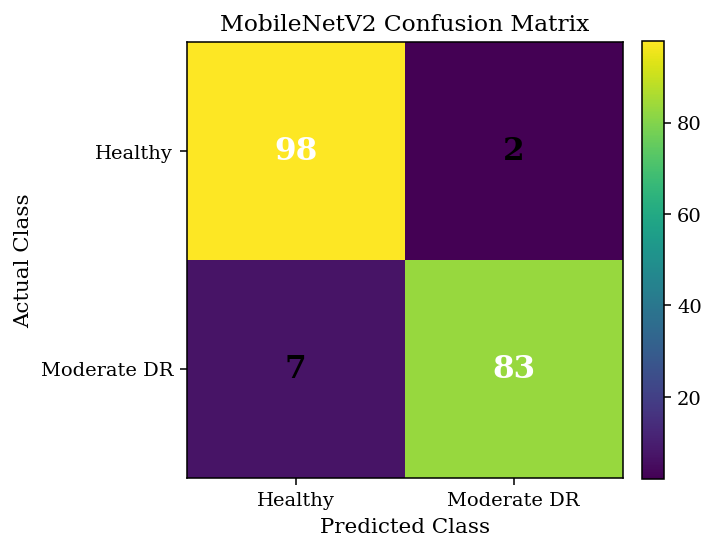

In [ ]:
# CELL 15 — Clean confusion matrices
def draw_cm(cm, model, stem):
    fig, ax = plt.subplots(figsize=(5.0, 4.3))
    im = ax.imshow(cm, interpolation="nearest")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax.set_xticks([0,1], CLASS_NAMES)
    ax.set_yticks([0,1], CLASS_NAMES)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.set_title(f"{model} Confusion Matrix")

    threshold = cm.max()/2
    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, str(cm[i,j]),
                ha="center", va="center",
                fontsize=16, fontweight="bold",
                color="white" if cm[i,j] > threshold else "black"
            )

    plt.tight_layout()
    plt.savefig(os.path.join(OUT, stem+".png"), dpi=600, bbox_inches="tight")
    plt.savefig(os.path.join(OUT, stem+".pdf"), bbox_inches="tight")
    plt.show()

draw_cm(x_cm, "Xception", "Fig4a_Xception_confusion_matrix")
draw_cm(m_cm, "MobileNetV2", "Fig4b_MobileNetV2_confusion_matrix")


## 8. Redraw Fig. 6 — accuracy with bootstrap 95% CIs

Use this caption in the paper:

> **Fig. 6.** Test-set classification accuracy of Xception and MobileNetV2. Error bars indicate non-parametric 95% bootstrap confidence intervals over the fixed test set. These intervals quantify test-sample uncertainty and do not represent variability across independent training runs.


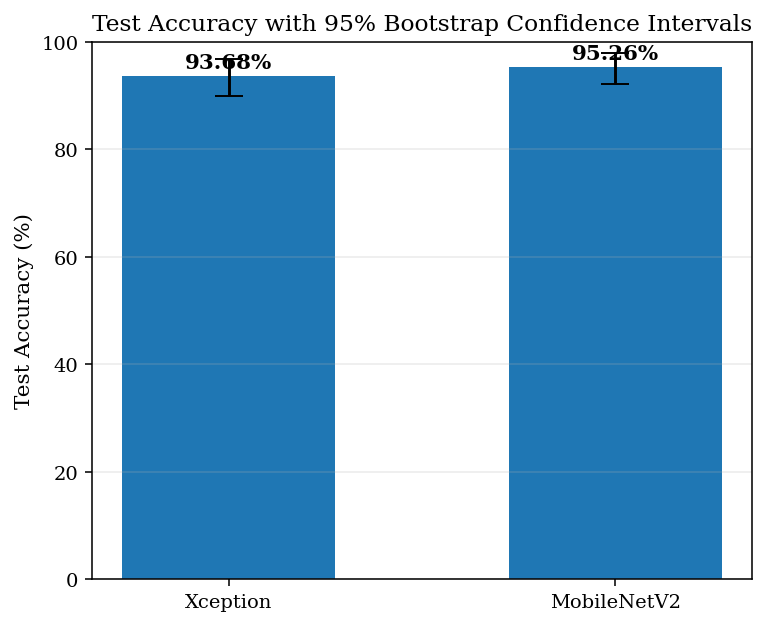

In [ ]:
# CELL 16 — Fig. 6
labels = ["Xception", "MobileNetV2"]
points = np.array([x_boot["point"], m_boot["point"]]) * 100

lower = np.array([
    x_boot["point"] - x_boot["lower"],
    m_boot["point"] - m_boot["lower"]
]) * 100

upper = np.array([
    x_boot["upper"] - x_boot["point"],
    m_boot["upper"] - m_boot["point"]
]) * 100

fig, ax = plt.subplots(figsize=(5.6, 4.6))
bars = ax.bar(labels, points, yerr=np.vstack([lower, upper]), capsize=7, width=0.55)

ax.set_ylabel("Test Accuracy (%)")
ax.set_title("Test Accuracy with 95% Bootstrap Confidence Intervals")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)

for b, value in zip(bars, points):
    ax.text(
        b.get_x()+b.get_width()/2,
        min(value+1.5, 98.5),
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.savefig(os.path.join(OUT, "Fig6_revised_accuracy_bootstrap_CI.png"), dpi=600, bbox_inches="tight")
plt.savefig(os.path.join(OUT, "Fig6_revised_accuracy_bootstrap_CI.pdf"), bbox_inches="tight")
plt.show()


## 9. Optional: recover TFLite probabilities for a fresh ROC curve (Fig. 5)

ROC/AUC requires continuous model scores. The saved test spreadsheets may contain only hard labels, so this section re-runs the **saved TFLite models** on the fixed test images.

To avoid silently assuming the wrong preprocessing, it tries three plausible input scalings and checks which one best reproduces the already-saved hard predictions:

- `[0,1]`
- `[-1,1]`
- raw `[0,255]`

Only use the regenerated ROC/AUC in the manuscript if TFLite hard predictions reproduce the saved test predictions very closely (recommended threshold: ≥99% agreement).


In [ ]:
# CELL 17 — Index test images
def index_test_images(folder):
    by_stem = {}
    by_name = {}
    for f in Path(folder).rglob("*"):
        if f.is_file() and f.suffix.lower() in VALID_EXT:
            by_stem[f.stem.lower()] = str(f)
            by_name[f.name.lower()] = str(f)
    return by_stem, by_name

by_stem, by_name = index_test_images(TEST_DIR)

def resolve_path(v):
    p = Path(str(v))
    if p.name.lower() in by_name:
        return by_name[p.name.lower()]
    if p.stem.lower() in by_stem:
        return by_stem[p.stem.lower()]
    return None

x_test["filepath"] = x_test.image_original.map(resolve_path)
m_test["filepath"] = m_test.image_original.map(resolve_path)

print("Xception matched:", x_test.filepath.notna().sum(), "/", len(x_test))
print("MobileNetV2 matched:", m_test.filepath.notna().sum(), "/", len(m_test))


Xception matched: 190 / 190
MobileNetV2 matched: 190 / 190


In [ ]:
# CELL 18 — TFLite inference helpers
import tensorflow as tf

def preprocess(arr, mode):
    if mode == "0_1":
        return arr/255.0
    if mode == "minus1_1":
        return arr/127.5 - 1.0
    if mode == "raw_255":
        return arr
    raise ValueError(mode)

def run_tflite(model_path, df, mode):
    interpreter = tf.lite.Interpreter(model_path=model_path)
    interpreter.allocate_tensors()

    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]

    h, w = int(inp["shape"][1]), int(inp["shape"][2])

    preds, probs = [], []

    for fp in df.filepath:
        if pd.isna(fp):
            preds.append(np.nan)
            probs.append(np.nan)
            continue

        arr = np.asarray(Image.open(fp).convert("RGB").resize((w,h))).astype(np.float32)
        arr = preprocess(arr, mode)

        dtype = inp["dtype"]
        scale, zp = inp["quantization"]

        if np.issubdtype(dtype, np.integer):
            arr = np.round(arr/scale + zp)
            info = np.iinfo(dtype)
            arr = np.clip(arr, info.min, info.max).astype(dtype)
        else:
            arr = arr.astype(dtype)

        interpreter.set_tensor(inp["index"], arr[None,...])
        interpreter.invoke()

        y = np.asarray(interpreter.get_tensor(out["index"])).squeeze().astype(float).reshape(-1)

        oscale, ozp = out["quantization"]
        if np.issubdtype(out["dtype"], np.integer) and oscale != 0:
            y = (y - ozp) * oscale

        if len(y) == 1:
            p1 = float(y[0])
            pred = int(p1 >= 0.5)
        elif len(y) == 2:
            if np.any(y < 0) or not np.isclose(y.sum(), 1.0, atol=1e-3):
                z = y - y.max()
                y = np.exp(z)/np.exp(z).sum()
            pred = int(np.argmax(y))
            p1 = float(y[1])
        else:
            raise ValueError(f"Unexpected output shape: {y.shape}")

        preds.append(pred)
        probs.append(p1)

    return np.asarray(preds), np.asarray(probs)

def find_best_mode(model_path, df, model_name):
    best = None
    rows = []

    for mode in ["0_1", "minus1_1", "raw_255"]:
        pred, prob = run_tflite(model_path, df, mode)
        valid = ~pd.isna(pred)

        agreement = np.mean(
            pred[valid].astype(int) == df.loc[valid, "pred_label"].to_numpy()
        )

        rows.append({"model": model_name, "mode": mode, "agreement": agreement})

        if best is None or agreement > best["agreement"]:
            best = {"mode": mode, "agreement": agreement, "pred": pred, "prob": prob}

    display(pd.DataFrame(rows))
    print(model_name, "selected mode:", best["mode"], "agreement:", f"{best['agreement']*100:.2f}%")
    return best

x_best = find_best_mode(X_TFLITE, x_test, "Xception")
m_best = find_best_mode(M_TFLITE, m_test, "MobileNetV2")


,model,mode,agreement
0,Xception,0_1,0.984211
1,Xception,minus1_1,0.947368
2,Xception,raw_255,0.473684


Xception selected mode: 0_1 agreement: 98.42%


,model,mode,agreement
0,MobileNetV2,0_1,0.957895
1,MobileNetV2,minus1_1,0.921053
2,MobileNetV2,raw_255,0.526316


MobileNetV2 selected mode: 0_1 agreement: 95.79%


In [ ]:
# CELL 19 — Fig. 5: regenerate ROC only if TFLite predictions reproduce saved predictions
THRESHOLD = 0.99

if x_best["agreement"] >= THRESHOLD and m_best["agreement"] >= THRESHOLD:
    x_test["probability"] = x_best["prob"]
    m_test["probability"] = m_best["prob"]

    fig, ax = plt.subplots(figsize=(6.2, 5.0))

    for df, name in [(x_test, "Xception"), (m_test, "MobileNetV2")]:
        fpr, tpr, _ = roc_curve(df.true_label, df.probability)
        auc = roc_auc_score(df.true_label, df.probability)
        ax.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc:.3f})")

    ax.plot([0,1], [0,1], "--", linewidth=1.2, label="Chance")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("ROC Curves — Healthy vs Moderate DR")
    ax.set_xlim(0,1)
    ax.set_ylim(0,1.02)
    ax.grid(alpha=0.25)
    ax.legend(loc="lower right")

    plt.tight_layout()
    plt.savefig(os.path.join(OUT, "Fig5_revised_ROC_curves.png"), dpi=600, bbox_inches="tight")
    plt.savefig(os.path.join(OUT, "Fig5_revised_ROC_curves.pdf"), bbox_inches="tight")
    plt.show()
else:
    print("ROC regeneration skipped.")
    print("One or both TFLite models did not reproduce the saved hard predictions at >=99%.")
    print("Confirm the original image preprocessing before using a newly generated ROC curve.")


ROC regeneration skipped.
One or both TFLite models did not reproduce the saved hard predictions at >=99%.
Confirm the original image preprocessing before using a newly generated ROC curve.


## 10. Fig. 3 — readable representative predictions

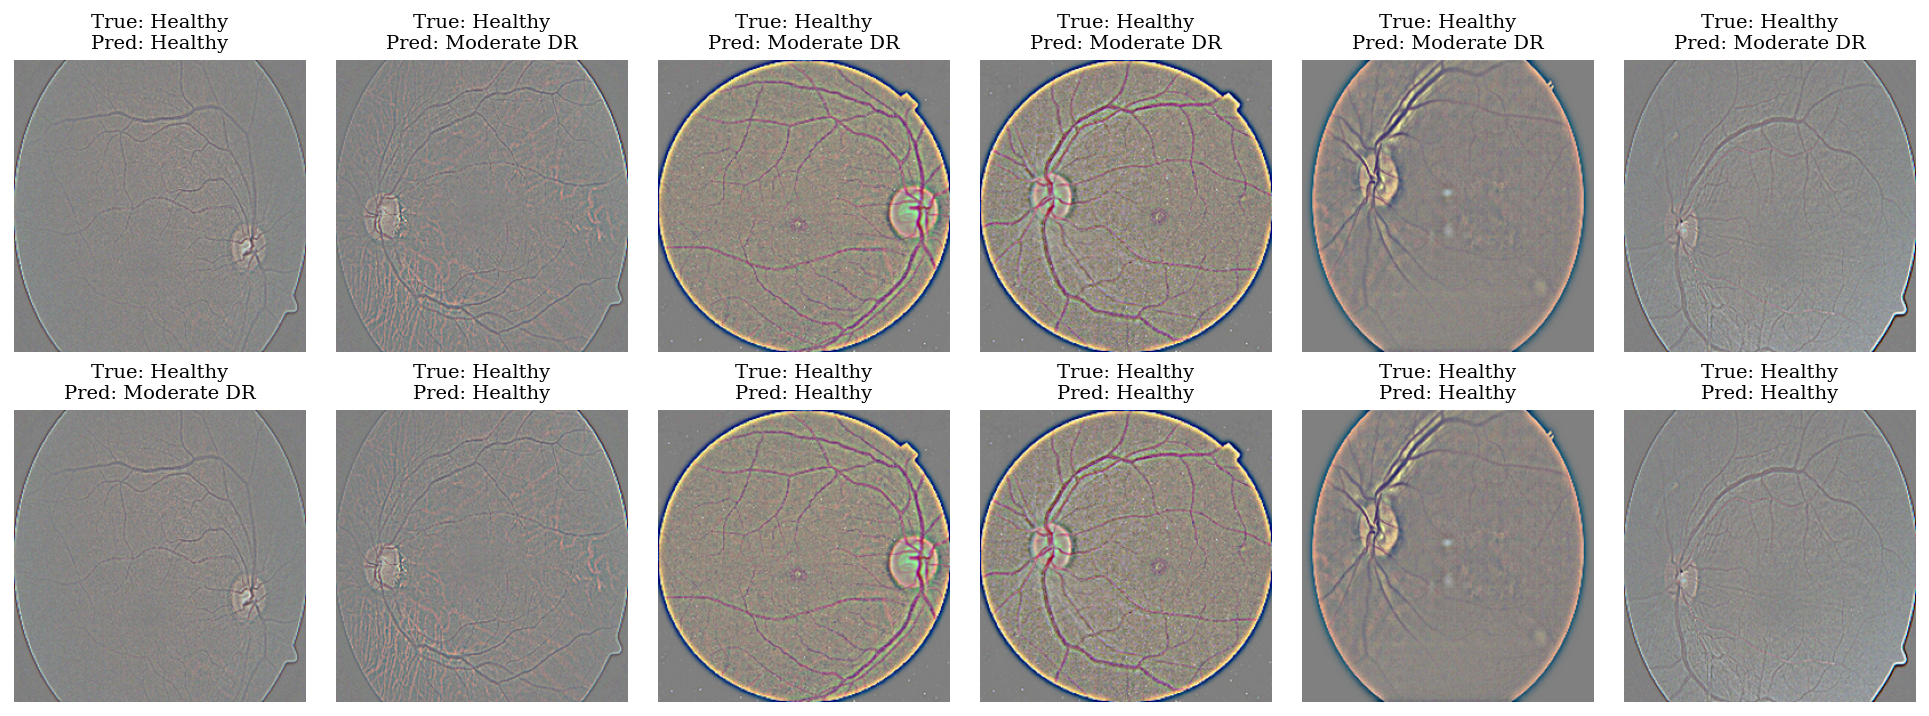

In [ ]:
# CELL 20 — Generate representative prediction grid
path_map = dict(zip(x_test.image_key, x_test.filepath))
paired["filepath"] = paired.image_key.map(path_map)

informative = pd.concat([
    paired[paired.x_pred != paired.m_pred],
    paired[paired.both_wrong],
    paired[paired.both_correct]
]).drop_duplicates("image_key")

selected = informative[informative.filepath.notna()].head(6)

def cname(v):
    return CLASS_NAMES[int(v)]

n = len(selected)

if n:
    fig, axes = plt.subplots(2, n, figsize=(2.3*n, 5.0), constrained_layout=True)
    if n == 1:
        axes = np.asarray(axes).reshape(2,1)

    for j, (_, r) in enumerate(selected.iterrows()):
        img = Image.open(r.filepath).convert("RGB")

        axes[0,j].imshow(img)
        axes[0,j].axis("off")
        axes[0,j].set_title(
            f"True: {cname(r.true_label)}\nPred: {cname(r.x_pred)}",
            fontsize=10
        )

        axes[1,j].imshow(img)
        axes[1,j].axis("off")
        axes[1,j].set_title(
            f"True: {cname(r.true_label)}\nPred: {cname(r.m_pred)}",
            fontsize=10
        )

    axes[0,0].set_ylabel("Xception")
    axes[1,0].set_ylabel("MobileNetV2")

    plt.savefig(os.path.join(OUT, "Fig3_revised_representative_predictions.png"), dpi=600, bbox_inches="tight")
    plt.savefig(os.path.join(OUT, "Fig3_revised_representative_predictions.pdf"), bbox_inches="tight")
    plt.show()
else:
    print("Could not match saved result filenames to test images.")


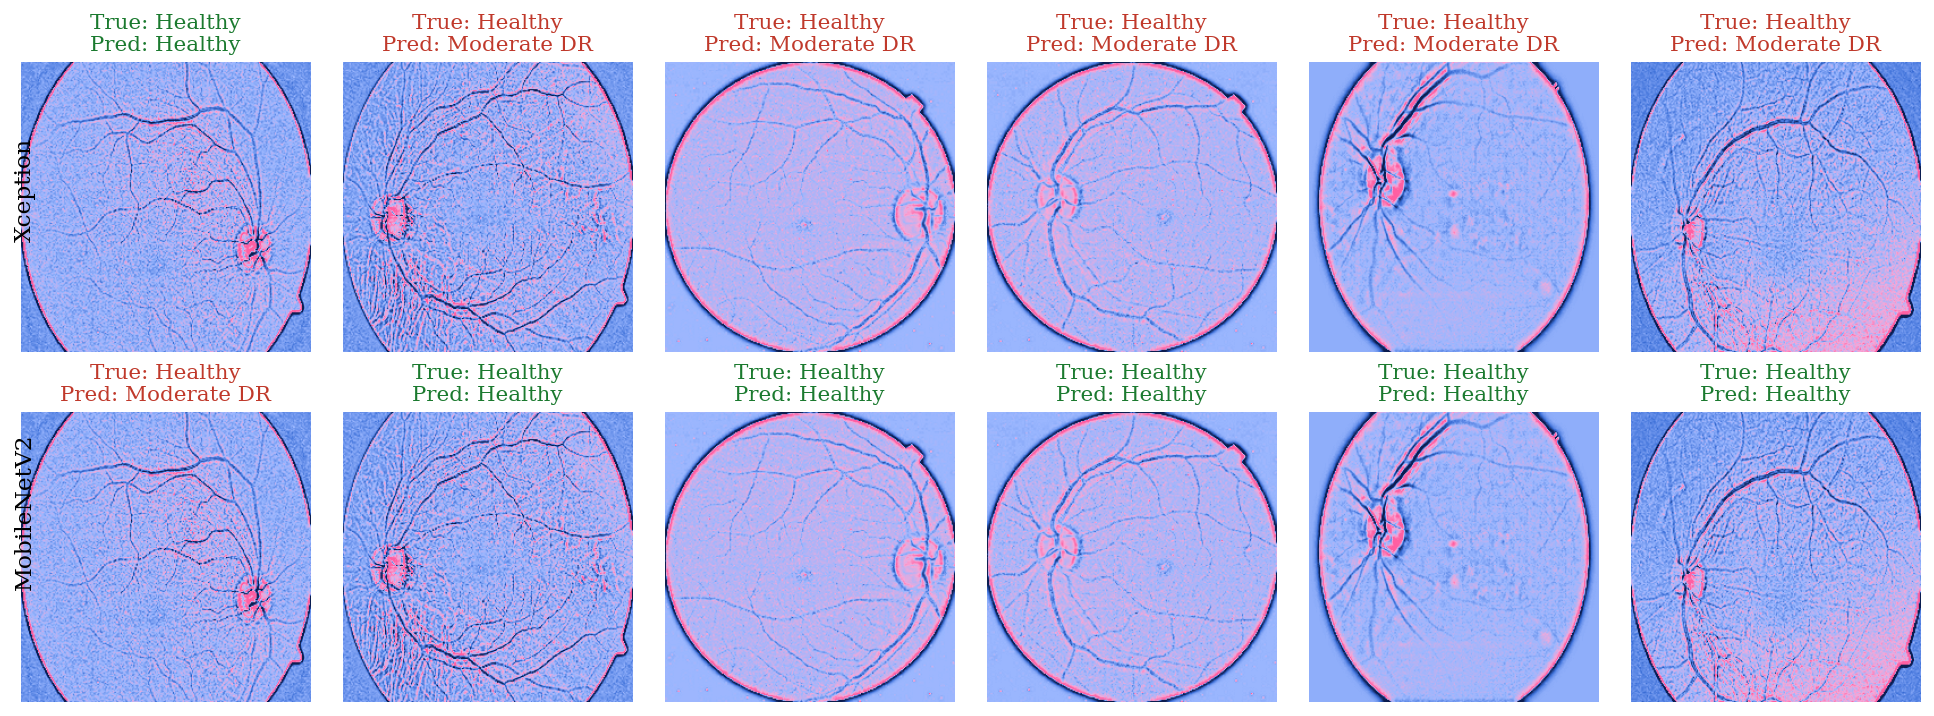

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

# ---- choose one palette ----
PALETTES = {
    "green_yellow": ["#06280f", "#1f7a3a", "#7dc95e", "#f2e55c", "#fff9b0"],
    "pink_blue":    ["#0b1d51", "#3b6fd8", "#9bb7ff", "#f7a8d8", "#ff5fa2"],
}
PALETTE = "pink_blue"          # or "green_yellow"
cmap = LinearSegmentedColormap.from_list(PALETTE, PALETTES[PALETTE], N=256)

def to_color(path, p_low=1, p_high=99):
    g = np.asarray(Image.open(path).convert("L")).astype(np.float32)
    lo, hi = np.percentile(g, [p_low, p_high])          # contrast stretch
    return np.clip((g - lo) / (hi - lo + 1e-8), 0, 1)

n = len(selected)

if n:
    fig, axes = plt.subplots(2, n, figsize=(2.3*n, 5.0), constrained_layout=True)
    if n == 1:
        axes = np.asarray(axes).reshape(2, 1)

    for j, (_, r) in enumerate(selected.iterrows()):
        g = to_color(r.filepath)
        for row, pred in [(0, r.x_pred), (1, r.m_pred)]:
            axes[row, j].imshow(g, cmap=cmap, vmin=0, vmax=1)
            axes[row, j].axis("off")
            ok = int(pred) == int(r.true_label)
            axes[row, j].set_title(
                f"True: {cname(r.true_label)}\nPred: {cname(pred)}",
                fontsize=11, color=("#1b7a2f" if ok else "#c0392b"))

    fig.text(0.005, 0.74, "Xception",    rotation=90, va="center", fontsize=12)
    fig.text(0.005, 0.28, "MobileNetV2", rotation=90, va="center", fontsize=12)

    plt.savefig(os.path.join(OUT, "Fig3_revised_representative_predictions.png"), dpi=600, bbox_inches="tight")
    plt.savefig(os.path.join(OUT, "Fig3_revised_representative_predictions.pdf"), bbox_inches="tight")
    plt.show()
else:
    print("Could not match saved result filenames to test images.")

## 11. Export revised statistics and reviewer-ready text

In [ ]:
# CELL 21 — Export summary tables
revision_summary = pd.DataFrame([
    {
        "Model": "Xception",
        "Test N": len(x_test),
        "Accuracy (%)": x_row["Accuracy (%)"],
        "Accuracy CI lower (%)": x_boot["lower"]*100,
        "Accuracy CI upper (%)": x_boot["upper"]*100,
        "Precision weighted (%)": x_row["Precision weighted (%)"],
        "Recall weighted (%)": x_row["Recall weighted (%)"],
        "F1 weighted (%)": x_row["F1 weighted (%)"]
    },
    {
        "Model": "MobileNetV2",
        "Test N": len(m_test),
        "Accuracy (%)": m_row["Accuracy (%)"],
        "Accuracy CI lower (%)": m_boot["lower"]*100,
        "Accuracy CI upper (%)": m_boot["upper"]*100,
        "Precision weighted (%)": m_row["Precision weighted (%)"],
        "Recall weighted (%)": m_row["Recall weighted (%)"],
        "F1 weighted (%)": m_row["F1 weighted (%)"]
    }
])

display(revision_summary)

revision_summary.to_csv(os.path.join(OUT, "revised_model_summary.csv"), index=False)
revision_summary.to_excel(os.path.join(OUT, "revised_model_summary.xlsx"), index=False)

paired.to_csv(os.path.join(OUT, "paired_model_predictions.csv"), index=False)
paired[paired.x_pred != paired.m_pred].to_csv(
    os.path.join(OUT, "model_disagreements.csv"),
    index=False
)

print("Saved revised tables to:", OUT)


,Model,Test N,Accuracy (%),Accuracy CI lower (%),Accuracy CI upper (%),Precision weighted (%),Recall weighted (%),F1 weighted (%)
0,Xception,190,93.684211,90.000000,96.842105,93.684211,93.684211,93.684211
1,MobileNetV2,190,95.263158,92.105263,97.894737,95.376677,95.263158,95.253255


Saved revised tables to: /content/drive/MyDrive/dr_datasets_indicon/revision_outputs


In [ ]:
# CELL 22 — Reviewer-response text
response = f"""
Reviewer comment:
The paired t-test is not justified because accuracy, precision, recall and F1
come from the same predictions. Please use McNemar's test and bootstrap
confidence intervals, or repeated seeds/k-fold cross-validation.

Response:
We thank the reviewer for this important observation. We agree that accuracy,
precision, recall, and F1-score derived from the same predictions should not be
pooled and treated as independent observations. We therefore removed the
previous pooled paired t-test. Because Xception and MobileNetV2 were evaluated
on the same held-out test images, we performed an exact McNemar test using the
paired classification outcomes. The exact McNemar p-value was {mc.pvalue:.4f}.

We additionally quantified uncertainty in test accuracy using 10,000
non-parametric bootstrap resamples of the fixed test set. Xception achieved
{x_boot['point']*100:.2f}% accuracy (95% bootstrap CI:
{x_boot['lower']*100:.2f}%–{x_boot['upper']*100:.2f}%), while MobileNetV2
achieved {m_boot['point']*100:.2f}% (95% bootstrap CI:
{m_boot['lower']*100:.2f}%–{m_boot['upper']*100:.2f}%). The paired accuracy
difference (MobileNetV2 minus Xception) was {d_boot['point']*100:.2f}
percentage points (95% paired bootstrap CI: {d_boot['lower']*100:.2f} to
{d_boot['upper']*100:.2f} percentage points).

Figure 6 has been redrawn so that the uncertainty measure is explicitly
defined as a non-parametric 95% bootstrap confidence interval over the fixed
test set. The previous mixed “95% CI” and “±2 SD” labeling has been removed.
"""

print(response)

with open(os.path.join(OUT, "reviewer_statistical_response.txt"), "w") as f:
    f.write(response)



Reviewer comment:
The paired t-test is not justified because accuracy, precision, recall and F1
come from the same predictions. Please use McNemar's test and bootstrap
confidence intervals, or repeated seeds/k-fold cross-validation.

Response:
We thank the reviewer for this important observation. We agree that accuracy,
precision, recall, and F1-score derived from the same predictions should not be
pooled and treated as independent observations. We therefore removed the
previous pooled paired t-test. Because Xception and MobileNetV2 were evaluated
on the same held-out test images, we performed an exact McNemar test using the
paired classification outcomes. The exact McNemar p-value was 0.5811.

We additionally quantified uncertainty in test accuracy using 10,000
non-parametric bootstrap resamples of the fixed test set. Xception achieved
93.68% accuracy (95% bootstrap CI:
90.00%–96.84%), while MobileNetV2
achieved 95.26% (95% bootstrap CI:
92.11%–97.89%). The paired accuracy
difference

# Final manuscript checklist

After running the notebook:

- Use the reconstructed confusion matrices and metrics as the authoritative consistency check.
- Replace the old pooled t-test with **McNemar's exact test**.
- State clearly that Fig. 6 uses **non-parametric bootstrap 95% CIs over the test set**.
- Do not describe those CIs as repeated-run variability.
- If original EyePACS patient identifiers are not preserved, do **not** claim patient-level independence unless you recover the original mapping.
- Avoid “minimal overfitting” if the validation-to-test difference is substantial.
- Distinguish **fewer total errors** from **more balanced class-wise errors**.
- Without external validation, prefer “held-out test performance” over broad claims of “generalization.”


In [ ]:
# ============================================================
# RECONSTRUCT ROC CURVES FROM SAVED TFLITE MODEL PROBABILITIES
# ============================================================

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np
import os

# We already found that 0_1 normalization gives the
# closest reproduction of the original experiment.

# Re-run inference explicitly using 0_1 normalization
x_pred_new, x_prob_new = run_tflite(
    X_TFLITE,
    x_test,
    mode="0_1"
)

m_pred_new, m_prob_new = run_tflite(
    M_TFLITE,
    m_test,
    mode="0_1"
)

# True labels
y_true_x = x_test["true_label"].to_numpy()
y_true_m = m_test["true_label"].to_numpy()

# ------------------------------------------------------------
# Calculate ROC coordinates
# ------------------------------------------------------------

x_fpr, x_tpr, x_thresholds = roc_curve(
    y_true_x,
    x_prob_new
)

m_fpr, m_tpr, m_thresholds = roc_curve(
    y_true_m,
    m_prob_new
)

# ------------------------------------------------------------
# Calculate AUC
# ------------------------------------------------------------

x_auc = roc_auc_score(
    y_true_x,
    x_prob_new
)

m_auc = roc_auc_score(
    y_true_m,
    m_prob_new
)

print("Reconstructed ROC-AUC")
print("=" * 50)

print(
    f"Xception AUC     : {x_auc:.4f}"
)

print(
    f"MobileNetV2 AUC  : {m_auc:.4f}"
)

Reconstructed ROC-AUC
Xception AUC     : 0.9834
MobileNetV2 AUC  : 0.9902


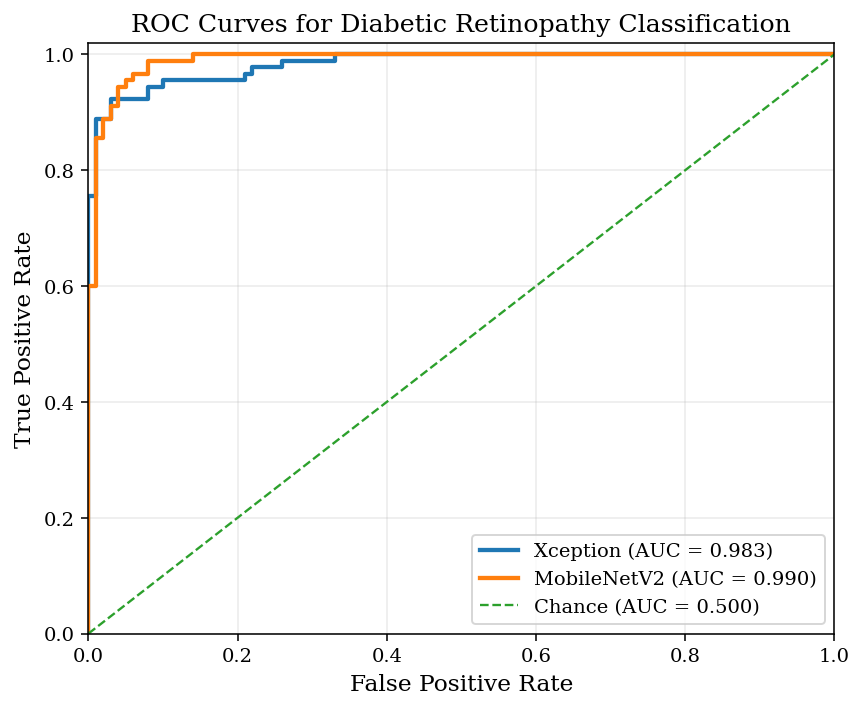

Saved:
/content/drive/MyDrive/dr_datasets_indicon/revision_outputs/Fig5_revised_ROC_curves.png
/content/drive/MyDrive/dr_datasets_indicon/revision_outputs/Fig5_revised_ROC_curves.pdf


In [ ]:
# ============================================================
# PUBLICATION-QUALITY COMBINED ROC CURVE
# ============================================================

plt.figure(
    figsize=(6.3, 5.2)
)

# Xception
plt.plot(
    x_fpr,
    x_tpr,
    linewidth=2.2,
    label=f"Xception (AUC = {x_auc:.3f})"
)

# MobileNetV2
plt.plot(
    m_fpr,
    m_tpr,
    linewidth=2.2,
    label=f"MobileNetV2 (AUC = {m_auc:.3f})"
)

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.2,
    label="Chance (AUC = 0.500)"
)

plt.xlabel(
    "False Positive Rate",
    fontsize=12
)

plt.ylabel(
    "True Positive Rate",
    fontsize=12
)

plt.title(
    "ROC Curves for Diabetic Retinopathy Classification",
    fontsize=13
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.grid(
    alpha=0.25
)

plt.legend(
    loc="lower right",
    fontsize=10,
    frameon=True
)

plt.tight_layout()

# Save high-resolution files
roc_png = os.path.join(
    OUT,
    "Fig5_revised_ROC_curves.png"
)

roc_pdf = os.path.join(
    OUT,
    "Fig5_revised_ROC_curves.pdf"
)

plt.savefig(
    roc_png,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    roc_pdf,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(roc_png)
print(roc_pdf)

In [ ]:
# ============================================================
# BOOTSTRAP 95% CONFIDENCE INTERVAL FOR AUC
# ============================================================

def bootstrap_auc_ci(
    y_true,
    y_prob,
    n_boot=10000,
    seed=42
):

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    rng = np.random.default_rng(
        seed
    )

    n = len(y_true)

    boot_auc = []

    for i in range(n_boot):

        idx = rng.integers(
            0,
            n,
            n
        )

        y_sample = y_true[idx]
        p_sample = y_prob[idx]

        # AUC cannot be calculated if
        # bootstrap sample contains only one class
        if len(np.unique(y_sample)) < 2:
            continue

        score = roc_auc_score(
            y_sample,
            p_sample
        )

        boot_auc.append(
            score
        )

    boot_auc = np.array(
        boot_auc
    )

    lower = np.percentile(
        boot_auc,
        2.5
    )

    upper = np.percentile(
        boot_auc,
        97.5
    )

    point = roc_auc_score(
        y_true,
        y_prob
    )

    return point, lower, upper

In [ ]:
x_auc, x_auc_low, x_auc_high = bootstrap_auc_ci(
    y_true_x,
    x_prob_new
)

m_auc, m_auc_low, m_auc_high = bootstrap_auc_ci(
    y_true_m,
    m_prob_new
)

print(
    f"Xception AUC = {x_auc:.3f} "
    f"(95% CI {x_auc_low:.3f}–{x_auc_high:.3f})"
)

print(
    f"MobileNetV2 AUC = {m_auc:.3f} "
    f"(95% CI {m_auc_low:.3f}–{m_auc_high:.3f})"
)

Xception AUC = 0.983 (95% CI 0.968–0.995)
MobileNetV2 AUC = 0.990 (95% CI 0.979–0.998)


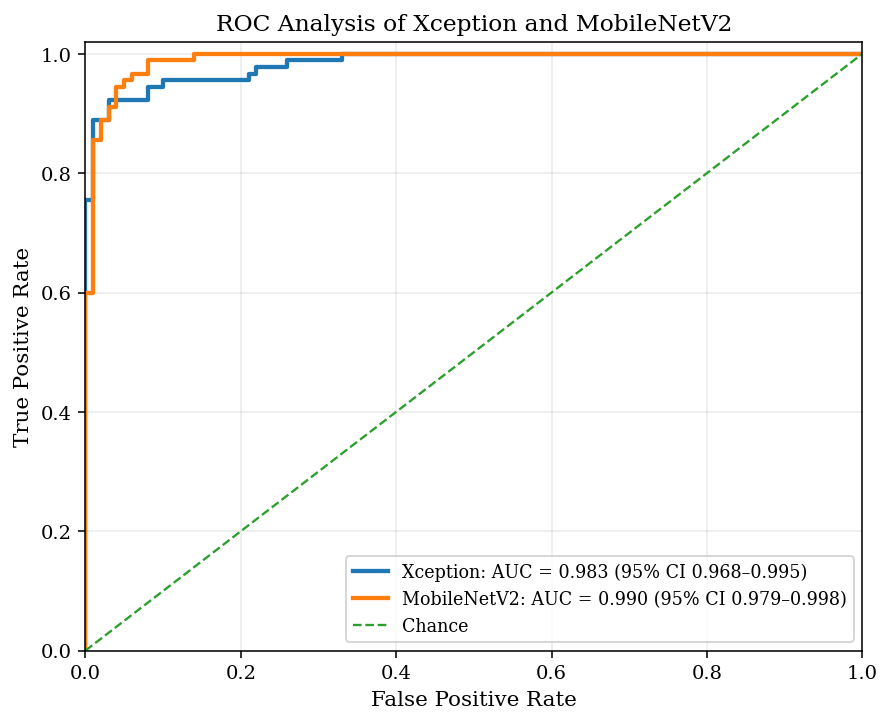

In [ ]:
plt.figure(figsize=(6.5, 5.3))

plt.plot(
    x_fpr,
    x_tpr,
    linewidth=2.2,
    label=(
        f"Xception: AUC = {x_auc:.3f} "
        f"(95% CI {x_auc_low:.3f}–{x_auc_high:.3f})"
    )
)

plt.plot(
    m_fpr,
    m_tpr,
    linewidth=2.2,
    label=(
        f"MobileNetV2: AUC = {m_auc:.3f} "
        f"(95% CI {m_auc_low:.3f}–{m_auc_high:.3f})"
    )
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    linewidth=1.2,
    label="Chance"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Analysis of Xception and MobileNetV2"
)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.grid(alpha=0.25)

plt.legend(
    loc="lower right",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT,
        "Fig5_ROC_AUC_with_95CI.png"
    ),
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        OUT,
        "Fig5_ROC_AUC_with_95CI.pdf"
    ),
    bbox_inches="tight"
)

plt.show()